### Grad-CAM Visualizations

To inspect the decisions made by our models, we use Grad-CAM (Gradient-weighted Class Activation Mapping).

It provides us with a way to look into what particular parts of the image influenced the whole model’s decision for a specifically assigned label (for an overview, see [this article](https://medium.com/@stepanulyanin/implementing-grad-cam-in-pytorch-ea0937c31e82)).

* **Tool:** `pytorch-grad-cam` library
* **Source Code:** [Official GitHub Repository](https://github.com/jacobgil/pytorch-grad-cam)

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget, RawScoresOutputTarget

from src.config import IMG_DIR, SPLITS_DIR
from src.data.preprocessing import preprocess_pipeline
from src.inference import InferencePipeline, REG_MODEL_PATH, CLF_MODEL_PATH, DEVICE

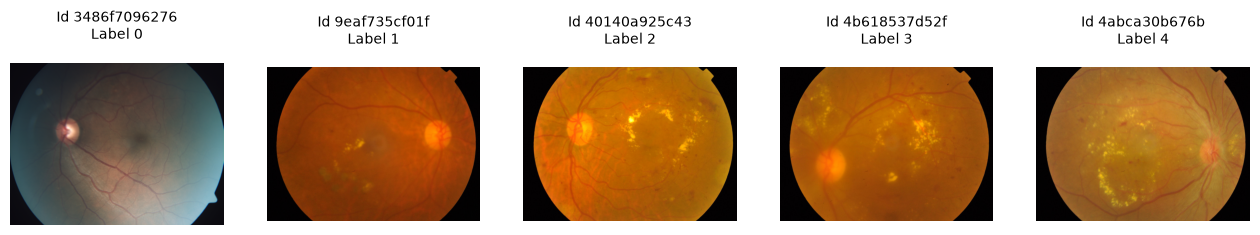

In [35]:
# Select random image from each class
test_df = pd.read_csv(SPLITS_DIR / "test_split.csv")
sampled_df = test_df.groupby('diagnosis').sample(n=1, random_state=42)

# Plot selected images
fig, axes = plt.subplots(1, 5, figsize=(16, 8))
axes = axes.flatten()

for i, row in enumerate(sampled_df.itertuples()):
    img_id = row.id_code
    img_label = row.diagnosis
    img_path = IMG_DIR / f"{img_id}.png"

    img = Image.open(img_path).convert("RGB")

    axes[i].imshow(img)
    axes[i].set_title(f"Id {img_id}\nLabel {img_label}", y=1.1, fontsize=10)
    axes[i].axis("off")

plt.show()

Let's generate a visualization grid for each sampled image:
1. Preprocessed image: the preprocessed image fed into the models.
2. Mask for classifier predicted class: Grad-CAM heatmap for the classifier's predicted class.
3. Mask for regressor prediction: Grad-CAM heatmap for the regression model (RawScoresOutputTarget).
4. Mask for classifier true class: displayed only when the classifier makes a mistake, showing what the classifier focused on when evaluated for the true class.

Id: 3486f7096276 | True: 0 | Clf: 0 (0.99) | Reg: 0.40 (0) | Ensemble: 0.15 (0)
Id: 9eaf735cf01f | True: 1 | Clf: 1 (0.98) | Reg: 2.30 (2) | Ensemble: 1.48 (1)
Id: 40140a925c43 | True: 2 | Clf: 2 (0.73) | Reg: 3.42 (3) | Ensemble: 2.74 (3) -> Error
Id: 4b618537d52f | True: 3 | Clf: 3 (0.81) | Reg: 4.04 (4) | Ensemble: 3.36 (3)
Id: 4abca30b676b | True: 4 | Clf: 2 (0.56) | Reg: 2.33 (2) | Ensemble: 2.42 (2) -> Error


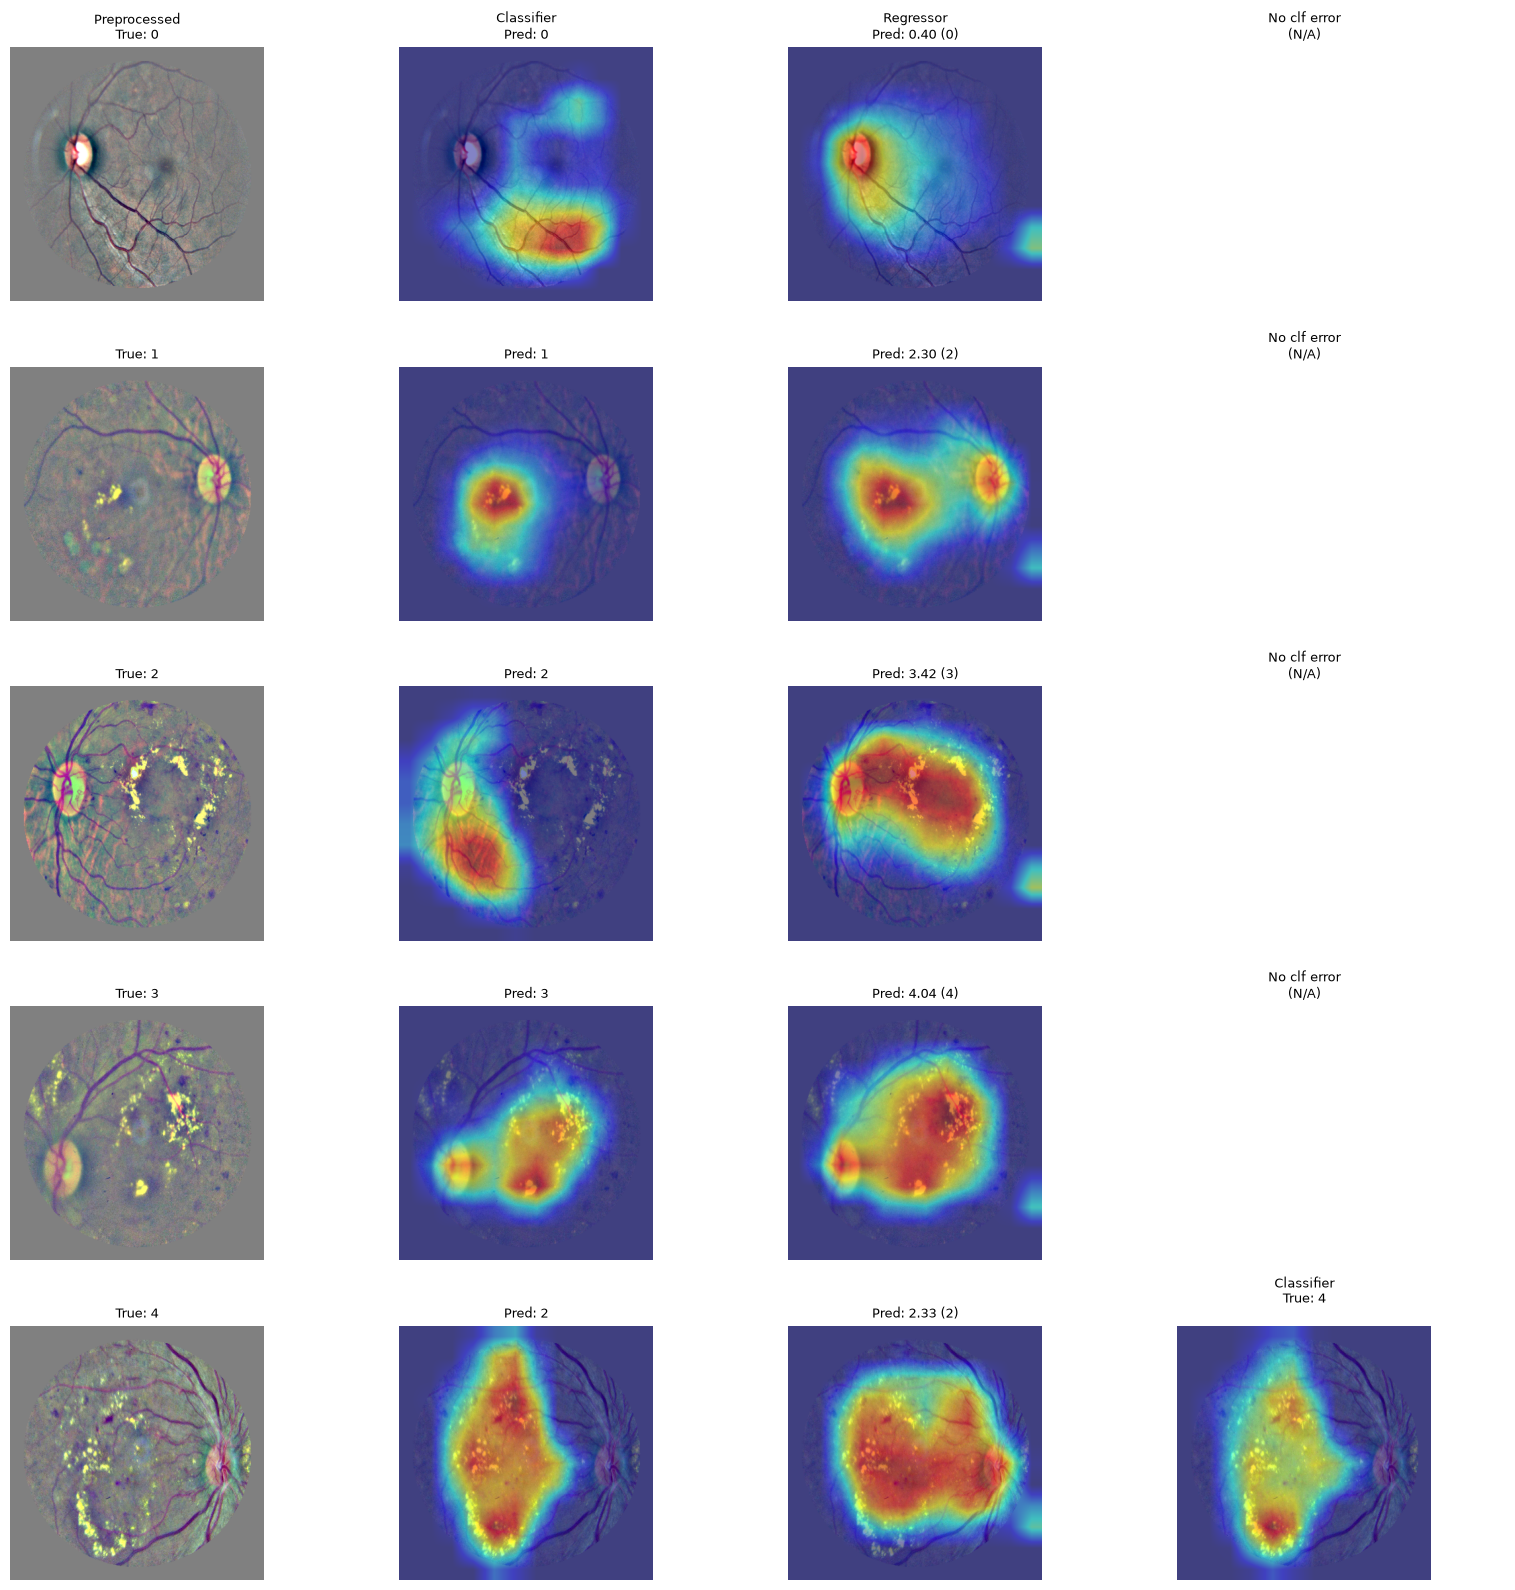

In [36]:
inference_pipeline = InferencePipeline(reg_model_path=REG_MODEL_PATH,
                                       clf_model_path=CLF_MODEL_PATH,
                                       device=DEVICE)

# Create plotting grid: 5 rows (classes), 4 columns
fig, axes = plt.subplots(5, 4, figsize=(16, 16))

target_layers_clf = [inference_pipeline.model_clf.model.conv_head]
target_layers_reg = [inference_pipeline.model_reg.model.conv_head]

# Flag indicating whether to use eigen_smooth (has effect of removing lots of noise)
USE_SMOOTHING = True

for i, row in enumerate(sampled_df.itertuples()):
    img_id = row.id_code
    img_label = row.diagnosis
    img_path = IMG_DIR / f"{img_id}.png"

    # Obtain inference results
    result = inference_pipeline.predict_single(img_path)
    clf_probs = torch.tensor(result["classification_probs"])
    clf_pred = torch.argmax(clf_probs).item()
    reg_out = torch.tensor(result["regression_pred"])
    reg_pred = int(torch.clamp(torch.round(reg_out), 0, 4).item())
    ensemble_raw = result["ensemble_score"]
    ensemble_pred = result["predicted_class"]

    # Display prediction details
    print(f"Id: {img_id} | True: {img_label} | Clf: {clf_pred} ({torch.max(clf_probs):.2f}) | "
          f"Reg: {reg_out:.2f} ({reg_pred}) | Ensemble: {ensemble_raw:.2f} ({ensemble_pred})"
          f"{' -> Error' if img_label != ensemble_pred else ''}")

    # Preprocessing (for Grad-CAM and displaying)
    img_np = preprocess_pipeline(img_path)
    img_float = img_np.astype(np.float32) / 255.0
    img_tensor = inference_pipeline.transform(img_np).unsqueeze(0).to(DEVICE)

    # Generate Grad-CAM for classifier (predicted class)
    targets_clf = [ClassifierOutputTarget(int(clf_pred))]
    with GradCAM(model=inference_pipeline.model_clf, target_layers=target_layers_clf) as cam:
        cam_clf = cam(
            input_tensor=img_tensor,
            targets=targets_clf,
            eigen_smooth=USE_SMOOTHING,
        )[0]
        vis_clf = show_cam_on_image(img_float, cam_clf, use_rgb=True)

    # Generate Grad-CAM for regressor
    targets_reg = [RawScoresOutputTarget()]
    with GradCAM(model=inference_pipeline.model_reg, target_layers=target_layers_reg) as cam:
        cam_reg = cam(
            input_tensor=img_tensor,
            targets=targets_reg,
            eigen_smooth=USE_SMOOTHING,
        )[0]
        vis_reg = show_cam_on_image(img_float, cam_reg, use_rgb=True)

    # If error, create map for true class (classifier model)
    vis_true_class = None
    clf_has_error = (img_label != clf_pred)
    if clf_has_error:
        targets_clf_true = [ClassifierOutputTarget(int(img_label))]
        with GradCAM(model=inference_pipeline.model_clf, target_layers=target_layers_clf) as cam:
            cam_true = cam(
                input_tensor=img_tensor,
                targets=targets_clf_true,
                eigen_smooth=USE_SMOOTHING,
            )[0]
            vis_true_class = show_cam_on_image(img_float, cam_true, use_rgb=True)

    # Display images
    axes[i][0].imshow(img_float)
    axes[i][1].imshow(vis_clf)
    axes[i][2].imshow(vis_reg)

    if clf_has_error and vis_true_class is not None:
        axes[i][3].imshow(vis_true_class)

    for j in range(4):
        axes[i][j].axis("off")

    # Set titles
    if i == 0:
        axes[i][0].set_title(f"Preprocessed\nTrue: {img_label}", fontsize=9)
        axes[i][1].set_title(f"Classifier\nPred: {clf_pred}", fontsize=9)
        axes[i][2].set_title(f"Regressor\nPred: {reg_out:.2f} ({reg_pred})", fontsize=9)
    else:
        axes[i][0].set_title(f"True: {img_label}", fontsize=9)
        axes[i][1].set_title(f"Pred: {clf_pred}", fontsize=9)
        axes[i][2].set_title(f"Pred: {reg_out:.2f} ({reg_pred})", fontsize=9)

    if clf_has_error:
        axes[i][3].set_title(f"Classifier\nTrue: {img_label}\n", fontsize=9)
    else:
        axes[i][3].set_title("No clf error\n(N/A)", fontsize=9)

plt.tight_layout()
plt.show()

What the image shows:
1. Class 0 (correctly predicted as normal): Both models correctly predict the stage. Looks like classifier focuses on normal blood vessels, while regressor does not highlight any region besides an optic disc.
2. Classes 1 & 3 (correctly predicted): Both models focus on regions with lesion spots. Regressor overestimates the stage, but the classifier (in the ensemble) shifts the prediction in the right direction.
3. Class 2 (incorrectly predicted as 3): The classifier does not highlight lesion spots in the center, yet correctly predicts the stage (interesting; model also relies on some other patterns?). The regressor highlights the center, but overestimates the stage (3.42).
4. Class 4 (incorrectly predicted as 2): Both models highlight lesion spots, but underestimate the stage. This is consistent with the low recall for class 4 in the confusion matrices (see `notebooks/05_modeling_experiments.ipynb`). The true-class Grad-CAM map (4th column) shows that the classifier does activate on the same lesion regions, but its activations for class 2 are stronger.

**General observation on Regressor:** Notice that the regressor consistently highlights the optic disc (uses it as a reference point? or any other reason?).